# Computational Intelligence Project
# Exercise 8. Evolution of cooperation

**Question:** Does cooperation emerge and persist as action noise increases?

**Hypothesis :** Higher noise reduces cooperation over generations 401–500.


In [1]:
import csv
import random

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Reuse the game rules and plotting functions

from ipd import (
    DEFAULT_SETTINGS, STRATEGIES, BITS, LABELS, NAMES,
    expected_match, simulate_match, build_matrices,
    make_toolbox, evaluate_population,
)

from run_experiment import (
    NOISE_LEVELS, run_study, read_matrix, load_results, make_comparisons,
    plot_matrix, plot_outcomes, plot_strategy_frequencies,
    plot_final_window, plot_classical_payoffs,
)

%matplotlib inline

settings = DEFAULT_SETTINGS.copy() # a normal Python dictionary

for name, value in settings.items():
    print(name, "=", value)

population = 100
generations = 500
rounds = 150
crossover_probability = 0.7
crossover_bit_probability = 0.5
mutation_bit_probability = 0.01
tournament_size = 3
elites = 2
final_window = 100


## 32 strategies

Use **0 = cooperate**, **1 = defect**.

| Gene | Meaning |
|---|---|
| 0 | First action |
| 1 | Next action after CC |
| 2 | Next action after CD |
| 3 | Next action after DC |
| 4 | Next action after DD |

Your own previous action comes first. If you see CD, the opponent sees DC.
There are 32 strategy types, numbered 0–31, and 100 population members.
Several individuals can use the same strategy.

In [2]:
# ID | Bits | Name

print("ID  Bits   Name")

for strategy_id, bits in enumerate(BITS):
    print(f"{strategy_id:02d}  {bits}  {NAMES.get(strategy_id, '')}")

ID  Bits   Name
00  00000  ALLC
01  00001  
02  00010  
03  00011  
04  00100  
05  00101  TFT
06  00110  PAVLOV
07  00111  
08  01000  
09  01001  
10  01010  
11  01011  
12  01100  
13  01101  
14  01110  
15  01111  
16  10000  
17  10001  
18  10010  
19  10011  
20  10100  
21  10101  
22  10110  
23  10111  
24  11000  
25  11001  
26  11010  
27  11011  
28  11100  
29  11101  
30  11110  
31  11111  ALLD


## Payoff A and cooperation H

**A[i, j]** gives the expected points per round for strategy i against strategy j.
For CC, CD, DC, DD, the row player's rewards are **3, 0, 5, 1**.

**H[i, j]** gives the expected fraction of both players' actions that cooperate.
CC contributes 1, CD and DC contribute 0.5, and DD contributes 0.

For example, ALLC against ALLD has A=0 for ALLC and H=0.5

In [3]:
# Compare reward and cooperation in a few simple matches

pairs = [(0, 0), (0, 31), (31, 0), (31, 31), (5, 31)]

for first, second in pairs:

    a, h = expected_match(STRATEGIES[first], STRATEGIES[second], noise=0)

    print(f"{LABELS[first]} vs {LABELS[second]}: A={a:.4f}, H={h:.4f}")

00: 00000 ("ALLC") vs 00: 00000 ("ALLC"): A=3.0000, H=1.0000
00: 00000 ("ALLC") vs 31: 11111 ("ALLD"): A=0.0000, H=0.5000
31: 11111 ("ALLD") vs 00: 00000 ("ALLC"): A=5.0000, H=0.5000
31: 11111 ("ALLD") vs 31: 11111 ("ALLD"): A=1.0000, H=0.0000
05: 00101 ("TFT") vs 31: 11111 ("ALLD"): A=0.9933, H=0.0033


## Obtain the matrices

We do the following for every pair of strategies:

1. Read their first bits to find their first intended moves.
2. Include the chance that either player makes a mistake. This gives the chances
   of CC, CD, DC, and DD.
3. For the next round, use each strategy's response to those possible outcomes.
4. Repeat for all 150 rounds, adding the expected points and cooperative actions.
5. Divide by the number of rounds to get one entry in A and H.

Repeat this for all 32 × 32 pairs, separately at noise 0, 0.01, and 0.05.


In [ ]:
# Calculate the matrices

matrices = {}

for noise in NOISE_LEVELS:

    A, H = build_matrices(noise, rounds=settings["rounds"])
    matrices[noise] = (A, H)


In [5]:
# Simulate actual games and compare their average with the calculation


payoffs, cooperation = simulate_match(
    STRATEGIES[5], STRATEGIES[5],
    noise=0.01,
    matches=10000,
    seed=123, # reproducible action errors
)

expected_a, expected_h = expected_match(STRATEGIES[5], STRATEGIES[5], noise=0.01)

print("Simulated average payoff:", round(np.mean(payoffs), 4))
print("Calculated payoff:", round(expected_a, 4))

print("Simulated cooperation:", round(np.mean(cooperation), 4))
print("Calculated cooperation:", round(expected_h, 4))


Simulated average payoff: 2.5247
Calculated payoff: 2.5206
Simulated cooperation: 0.6582
Calculated cooperation: 0.6554


## Inspect a matrix entry

Here we choose noise 0.01, row 5 (TFT), and column 6 (PAVLOV).
A[row_id, column_id] selects their payoff. The same position in H gives cooperation.

05: 00101 ("TFT") against 06: 00110 ("PAVLOV")
Expected payoff A: 2.4291208369162445
Cooperation H: 0.6203536616374816


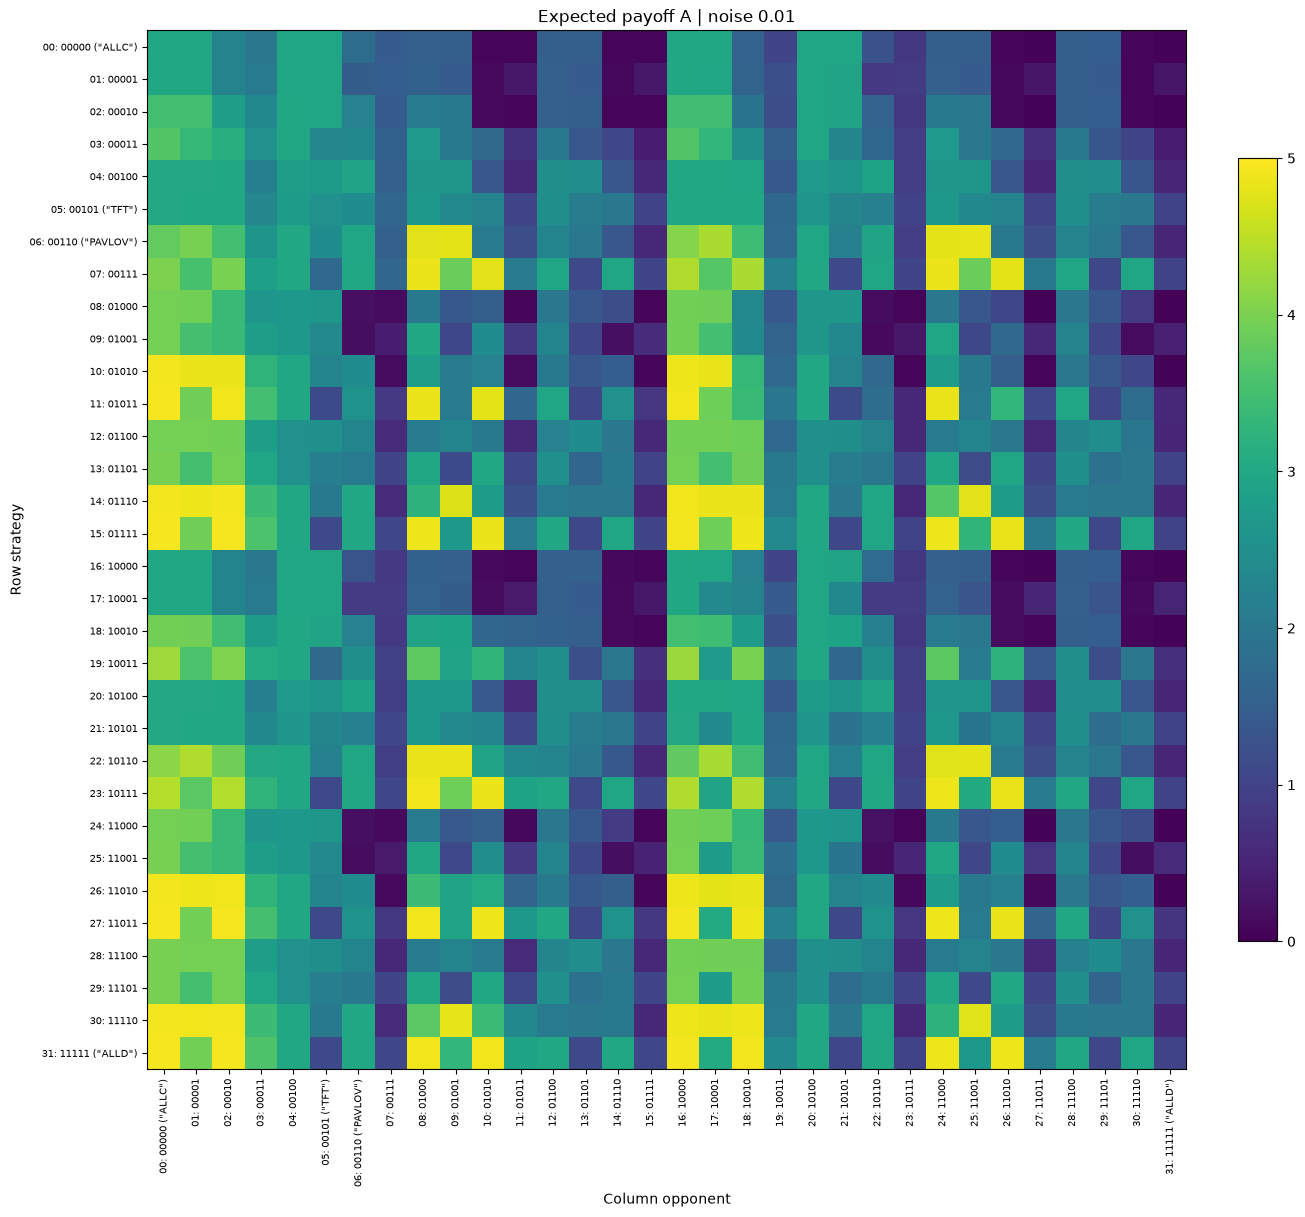

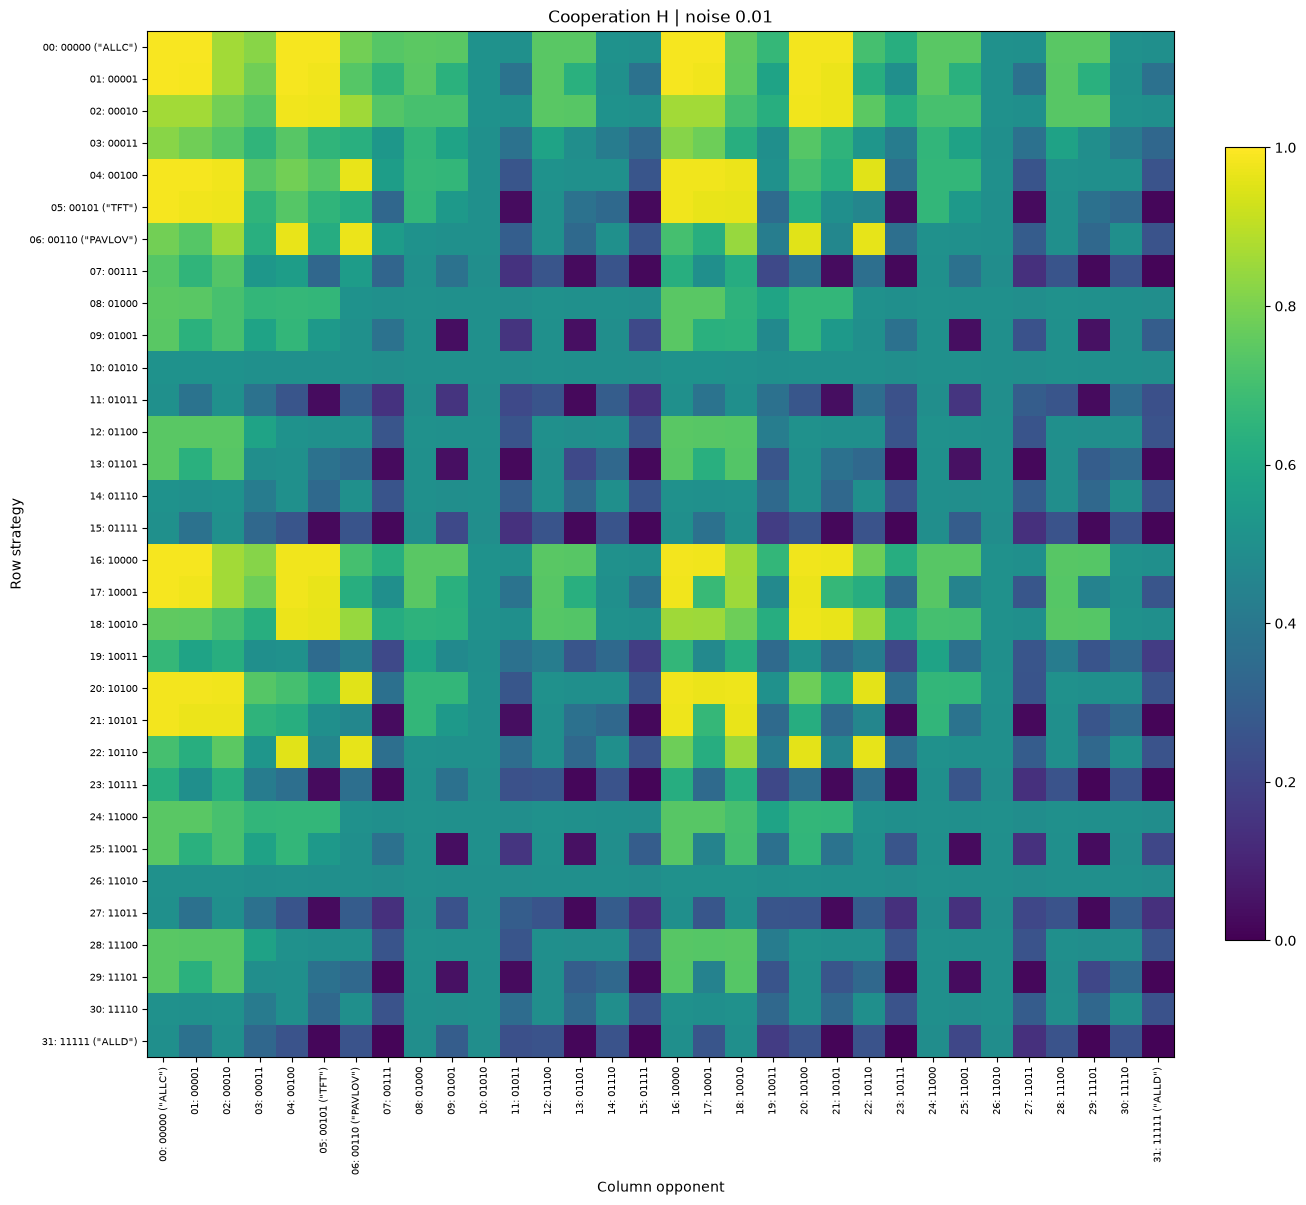

In [ ]:
# Choose two strategies to inspect

noise = 0.01
row_id, column_id = 5, 6 # TFT vs PAVLOV

A, H = matrices[noise] # Excpected payoff and cooperation

print(LABELS[row_id], "against", LABELS[column_id])
print("Expected payoff A:", A[row_id, column_id])

print("Cooperation H:", H[row_id, column_id])

# Display the full matrices 
figure = plot_matrix(A, noise, "A")
display(figure)
plt.close(figure)

figure = plot_matrix(H, noise, "H")
display(figure)
plt.close(figure)

## Create and evaluate 100 individuals

An individual is a five-bit strategy. DEAP stores its fitness alongside the bits.
The toolbox from deap gives us the functions for creating individuals, choosing parents,
crossover, and mutation.

Fitness is average payoff against the other 99 individuals.

For strategy i, `A[i] @ counts` adds its payoff against every type, weighted by
how many individuals use that type. 

`fitness = (A[i] @ counts - A[i, i]) / 99`

For example, an ALLD individual surrounded by 99 ALLC individuals has fitness 5
without noise. Surrounded by 99 ALLD individuals, it has fitness 1.


In [7]:
# Create a population of 100 individuals

random.seed(42) # reproducible

toolbox = make_toolbox(settings)
population = toolbox.population(n=settings["population"])

counts, payoff, cooperation = evaluate_population(population, A, H)

for individual in population:

    print(list(individual), "fitness:", round(individual.fitness.values[0], 4))

print("Population mean payoff:", round(payoff, 4))
print("Population cooperation (%):", round(cooperation * 100, 2))

# Tournament selection chooses parents

parents = toolbox.select(population, 2)

print("Two selected parents:", [list(parent) for parent in parents])

[0, 0, 1, 0, 0] fitness: 2.0965
[0, 0, 0, 1, 0] fitness: 1.7113
[0, 0, 0, 0, 0] fitness: 1.5449
[0, 1, 0, 1, 1] fitness: 2.5615
[0, 0, 1, 1, 1] fitness: 2.8806
[0, 0, 1, 0, 0] fitness: 2.0965
[1, 0, 1, 1, 1] fitness: 2.8981
[0, 1, 0, 1, 0] fitness: 2.0966
[1, 1, 0, 0, 0] fitness: 1.7422
[0, 1, 0, 0, 0] fitness: 1.7086
[1, 1, 1, 1, 0] fitness: 2.7493
[1, 1, 0, 1, 0] fitness: 2.3441
[0, 0, 0, 1, 1] fitness: 2.0106
[1, 0, 1, 0, 0] fitness: 2.0647
[0, 1, 1, 1, 0] fitness: 2.6556
[0, 1, 0, 1, 1] fitness: 2.5615
[1, 0, 1, 0, 0] fitness: 2.0647
[1, 1, 1, 1, 0] fitness: 2.7493
[0, 1, 0, 0, 0] fitness: 1.7086
[0, 0, 1, 0, 1] fitness: 2.1984
[1, 1, 1, 0, 0] fitness: 2.1432
[1, 1, 0, 1, 1] fitness: 2.7922
[0, 1, 0, 1, 0] fitness: 2.0966
[0, 1, 0, 0, 1] fitness: 1.8134
[0, 0, 1, 1, 0] fitness: 2.5619
[0, 1, 1, 0, 0] fitness: 2.137
[0, 0, 0, 1, 0] fitness: 1.7113
[0, 0, 1, 0, 1] fitness: 2.1984
[1, 0, 0, 1, 1] fitness: 2.478
[1, 1, 1, 0, 0] fitness: 2.1432
[0, 0, 1, 0, 0] fitness: 2.0965
[0, 0, 0, 

## The evolution loop

Start with 100 random individuals. Then:

1. Let everyone play the other 99 individuals and calculate their fitness.
2. Record the population's payoff, cooperation, and strategy counts.
3. Copy the two best individuals into the next population.
4. Choose parents for the other 98 places.
5. Repeat until we have made 500 new generations.

We calculate fitness again every generation because the opponents have changed.
The same strategy can do well in one population and poorly in another.


indpb=0.01 -> each bit has a 1% chance of changing.


## Results of the live 100-individual runs

Each run contains 100 individuals and 500 generations.

The table averages each run's last 100 generations. The first graph shows
cooperation and payoff over time. The second shows which strategies become common.

Noise | Cooperation (%) | Payoff per round
0 | 98.00 | 2.9789
0.01 | 25.49 | 1.5732
0.05 | 5.71 | 1.1680

Final counts at noise 0.0
00: 00000 ("ALLC") count: 0
01: 00001 count: 0
02: 00010 count: 0
03: 00011 count: 0
04: 00100 count: 9
05: 00101 ("TFT") count: 87
06: 00110 ("PAVLOV") count: 0
07: 00111 count: 0
08: 01000 count: 0
09: 01001 count: 0
10: 01010 count: 0
11: 01011 count: 0
12: 01100 count: 0
13: 01101 count: 3
14: 01110 count: 0
15: 01111 count: 0
16: 10000 count: 0
17: 10001 count: 0
18: 10010 count: 0
19: 10011 count: 0
20: 10100 count: 0
21: 10101 count: 1
22: 10110 count: 0
23: 10111 count: 0
24: 11000 count: 0
25: 11001 count: 0
26: 11010 count: 0
27: 11011 count: 0
28: 11100 count: 0
29: 11101 count: 0
30: 11110 count: 0
31: 11111 ("ALLD") count: 0


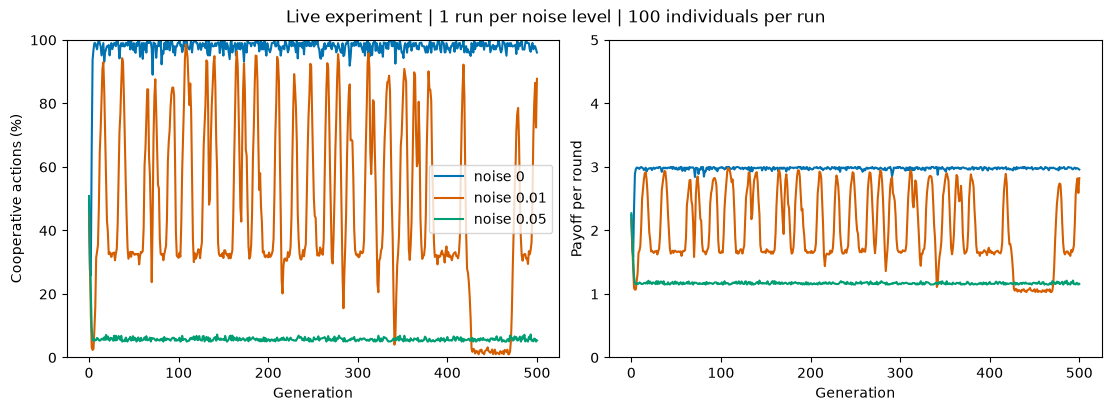

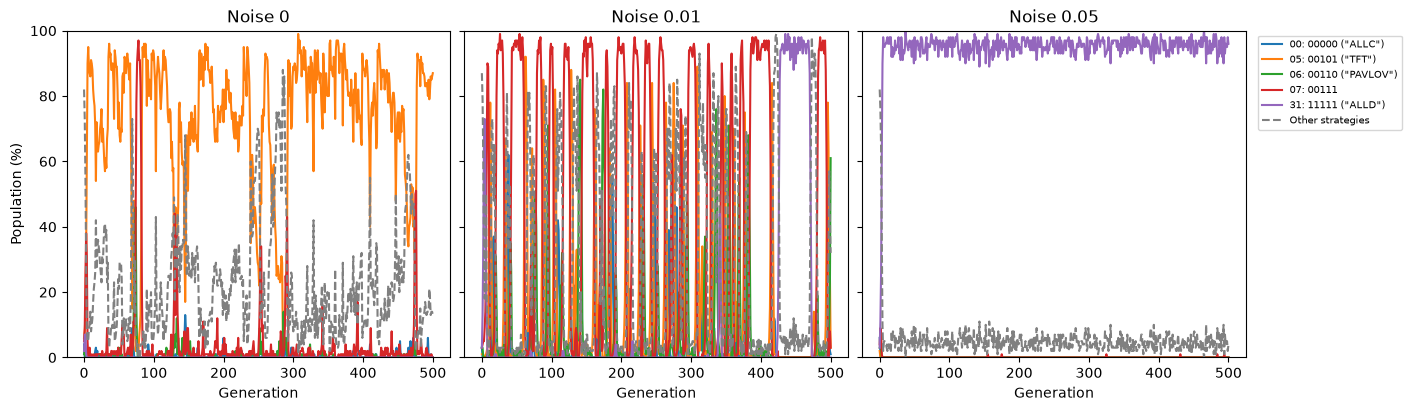

In [ ]:
# Show the final-window results

print("Noise | Cooperation (%) | Payoff per round")

for row in live_summaries:

    cooperation = row["window_cooperation"] * 100
    payoff = row["window_payoff"]

    print(f"{row['noise']:g} | {cooperation:.2f} | {payoff:.4f}")

# Show every strategy count in the first live run

first_run = live_summaries[0]

print("\nFinal counts at noise", first_run["noise"])

for strategy_id, bits in enumerate(BITS):
    print(LABELS[strategy_id], "count:", first_run[f"final_count_{bits}"])

# Display the results directly from memory

figure = plot_outcomes(live_histories)
display(figure)
plt.close(figure)

figure = plot_strategy_frequencies(live_histories)
display(figure)
plt.close(figure)

The full study already has results in results/.

In [10]:
# Read the saved matrices for the same two strategies

noise = 0.01
row_id, column_id = 5, 6

labels, saved_A = read_matrix(f"results/A_noise_{noise:g}.csv")
_, saved_H = read_matrix(f"results/H_noise_{noise:g}.csv") # labels are the same

print(labels[row_id], "against", labels[column_id])
print("Saved payoff A:", saved_A[row_id, column_id])
print("Saved cooperation H:", saved_H[row_id, column_id])

05: 00101 ("TFT") against 06: 00110 ("PAVLOV")
Saved payoff A: 2.4291208369162445
Saved cooperation H: 0.6203536616374816


## The full study

There are **30 independent runs at each noise level**. Every run starts with
100 individuals and evolves for 500 generations.

For each noise level, we collect its 30 run summaries and take the median—the
middle result after sorting.

In [11]:
# Read the summary table

with open("results/run_summary.csv", newline="", encoding="utf-8") as file:
    summaries = list(csv.DictReader(file))

# Convert CSV text into numbers

for row in summaries:

    for column in row:
        row[column] = float(row[column])

# Inspect the first saved run

first_run = summaries[0]

print("Noise:", first_run["noise"])
print("Run:", int(first_run["run"]))
print("Seed:", int(first_run["seed"]))

for strategy_id, bits in enumerate(BITS):
    print(LABELS[strategy_id], "final count:", int(first_run[f"final_count_{bits}"]))

# Compare the median results across repeated runs

print("\nNoise | Runs | Median cooperation (%) | Median payoff")

for noise in NOISE_LEVELS:

    group = []

    for row in summaries:
        if row["noise"] == noise:
            group.append(row)

    cooperation_values = [row["window_cooperation"] for row in group]
    payoff_values = [row["window_payoff"] for row in group]

    cooperation = np.median(cooperation_values) * 100
    payoff = np.median(payoff_values)

    print(f"{noise:g} | {len(group)} | {cooperation:.2f} | {payoff:.4f}")

Noise: 0.0
Run: 1
Seed: 21261112
00: 00000 ("ALLC") final count: 0
01: 00001 final count: 0
02: 00010 final count: 0
03: 00011 final count: 0
04: 00100 final count: 15
05: 00101 ("TFT") final count: 84
06: 00110 ("PAVLOV") final count: 0
07: 00111 final count: 0
08: 01000 final count: 0
09: 01001 final count: 0
10: 01010 final count: 0
11: 01011 final count: 0
12: 01100 final count: 0
13: 01101 final count: 0
14: 01110 final count: 0
15: 01111 final count: 0
16: 10000 final count: 0
17: 10001 final count: 0
18: 10010 final count: 0
19: 10011 final count: 0
20: 10100 final count: 0
21: 10101 final count: 1
22: 10110 final count: 0
23: 10111 final count: 0
24: 11000 final count: 0
25: 11001 final count: 0
26: 11010 final count: 0
27: 11011 final count: 0
28: 11100 final count: 0
29: 11101 final count: 0
30: 11110 final count: 0
31: 11111 ("ALLD") final count: 0

Noise | Runs | Median cooperation (%) | Median payoff
0 | 30 | 97.99 | 2.9777
0.01 | 30 | 47.18 | 2.0195
0.05 | 30 | 9.96 | 1.2

## Results in 100-individual runs

Each condition combines 30 runs, with 100 individuals in every run.
In the cooperation and payoff graph, the line is the median. The shaded region
goes from the smallest to the largest value among those runs.

The dots in the final figure show each run's average over generations 401–500.
Each dot represents a whole run, not one individual. The black bar marks the median.

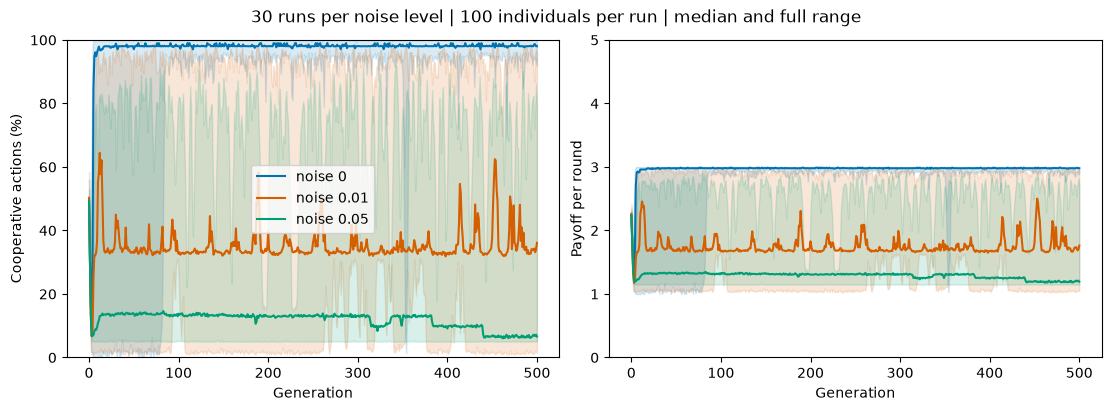

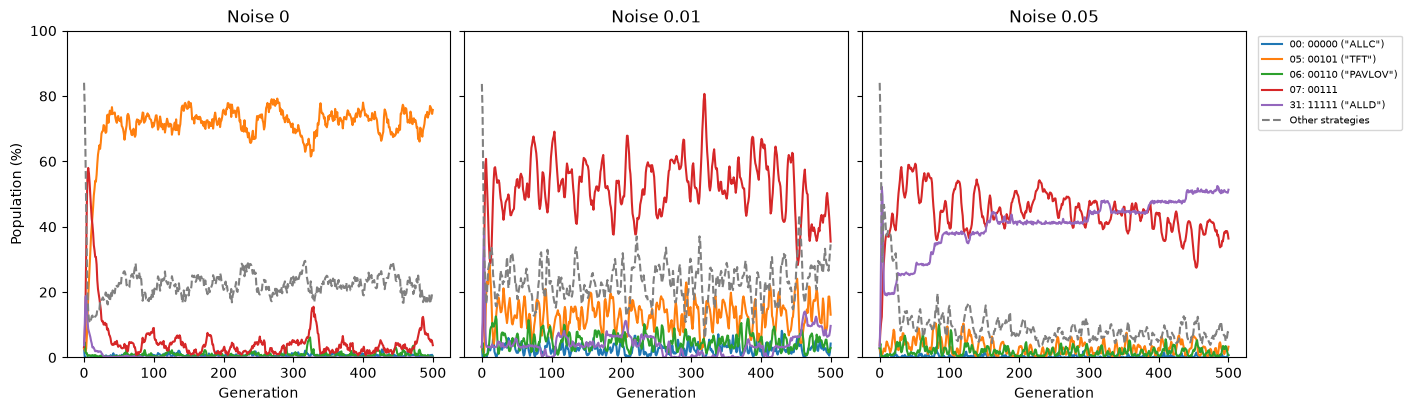

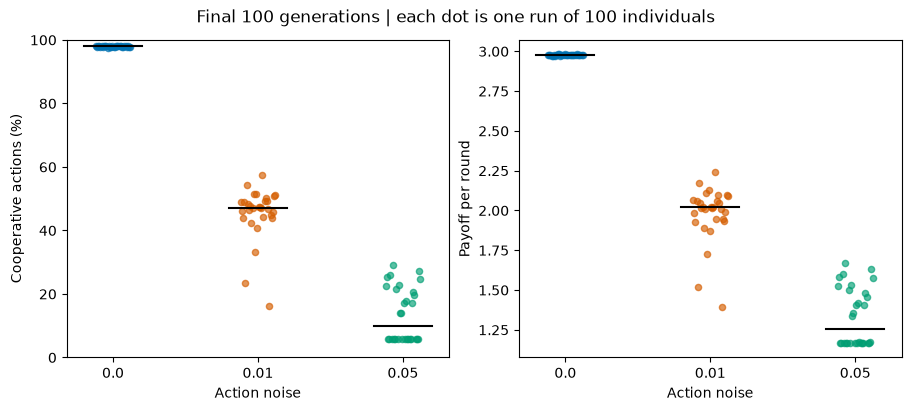

In [12]:
# Load the saved histories for plotting

study_histories, _, study_matrices = load_results("results")

figure = plot_outcomes(study_histories)
display(figure)
plt.close(figure)

figure = plot_strategy_frequencies(study_histories)
display(figure)
plt.close(figure)

figure = plot_final_window(summaries)
display(figure)
plt.close(figure)

## Differences and uncertainty

We subtract the zero-noise result from each noisy result. A negative cooperation
difference means that adding noise reduced cooperation.

To see how much the answer could vary, we randomly pick new groups from the runs
we already have, allowing a run to be picked more than once. We repeat this 5000
times and calculate the difference each time.

- **ci95_low:** the lower end of that interval.
- **ci95_high:** the upper end.
- **bootstrap_samples:** the number of resampled groups, here 5000.

These 5000 samples reuse existing results, they do not run evolution again.


In [13]:
# Calculate comparisons in memory, without writing comparisons.csv

comparisons = make_comparisons(summaries)

for row in comparisons:

    effect = row["median_difference"]
    low = row["ci95_low"]
    high = row["ci95_high"]

    if row["measure"] == "window_cooperation":

        effect, low, high = effect * 100, low * 100, high * 100
        unit = "percentage points of cooperation"

    else:
        unit = "payoff points per round"

    print(f"Noise {row['treatment_noise']:g} minus zero noise")
    print(f"Difference: {effect:.2f} {unit}")
    print(f"95% interval: {low:.2f} to {high:.2f}\n")

Noise 0.01 minus zero noise
Difference: -50.81 percentage points of cooperation
95% interval: -52.26 to -48.89

Noise 0.05 minus zero noise
Difference: -88.03 percentage points of cooperation
95% interval: -92.26 to -79.15

Noise 0.01 minus zero noise
Difference: -0.96 payoff points per round
95% interval: -0.99 to -0.92

Noise 0.05 minus zero noise
Difference: -1.72 payoff points per round
95% interval: -1.81 to -1.54



## Strategy counts

Counts tell us which strategies spread. Below we list the most common types over
the final 100 generations of the saved runs.



Noise 0: average number of individuals, out of 100
05: 00101 ("TFT") 72.08
04: 00100 17.35
07: 00111 3.75
01: 00001 2.86
06: 00110 ("PAVLOV") 1.06

Noise 0.01: average number of individuals, out of 100
07: 00111 48.45
05: 00101 ("TFT") 13.79
31: 11111 ("ALLD") 6.13
01: 00001 6.05
04: 00100 5.65

Noise 0.05: average number of individuals, out of 100
31: 11111 ("ALLD") 49.63
07: 00111 38.13
05: 00101 ("TFT") 2.83
06: 00110 ("PAVLOV") 1.79
04: 00100 1.33


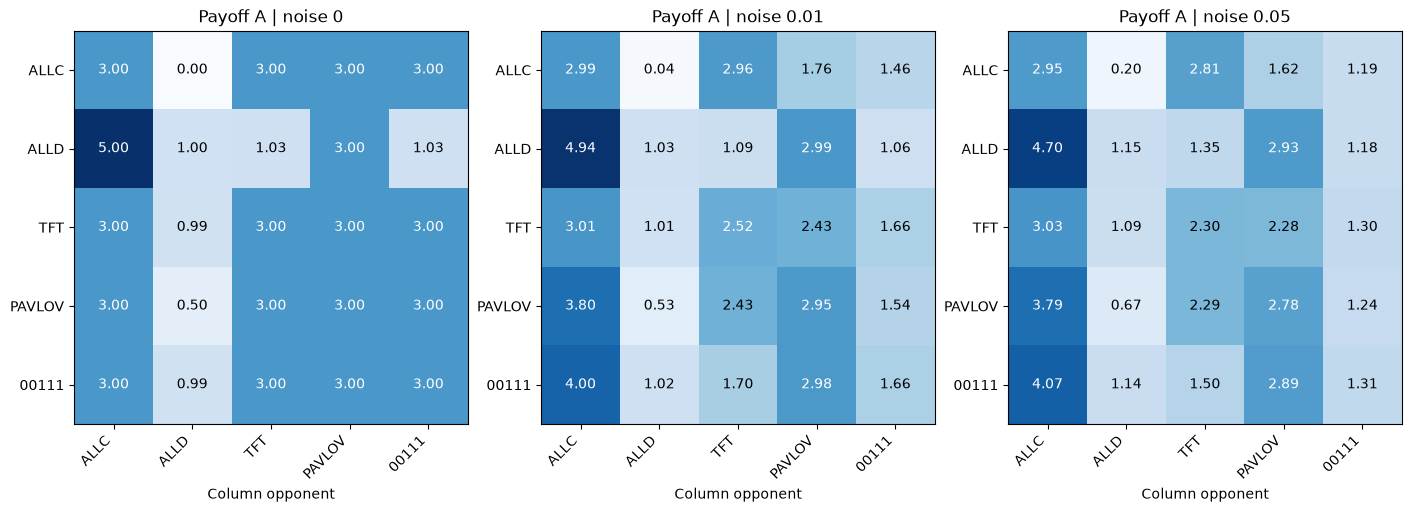

In [14]:
# Find the most common types in the saved repeated study

for noise in NOISE_LEVELS:

    group = [row for row in summaries if row["noise"] == noise]
    mean_counts = []

    for bits in BITS:

        counts = [row[f"window_mean_count_{bits}"] for row in group]
        mean_counts.append(np.mean(counts))

    most_common = np.argsort(mean_counts)[::-1][:5]

    print(f"\nNoise {noise:g}: average number of individuals, out of 100")

    for strategy_id in most_common:
        print(LABELS[strategy_id], round(mean_counts[strategy_id], 2))

figure = plot_classical_payoffs(matrices)
display(figure)
plt.close(figure)